# EDA и проверка статистических гипотез

## Подготовка данных

### Чистка данных

In [ ]:
import re

import numpy as np
import pandas as pd
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df_raw = pd.read_csv("top2000video.csv")
df_raw.head(6)


,Unnamed: 0,url,title,count_views,duration,hotspots,likes_up,likes_down,date,categories,tags,count_comments
0,0,https://www.pornhub.com/view_video.php?viewkey...,Playing a New Game With Hot Step Sister - Anas...,219601885,0:28:50,"[913424094, 16357614, 13353896, 12170463, 1115...",760553,217643,2018-02-22 20:41:12,"['amateur', 'babe', 'blonde', 'creampie', 'por...","[Tag(name='point of view'), Tag(name='step fuc...",818
1,1,https://www.pornhub.com/view_video.php?viewkey...,Kimmy Granger Likes it Rough,127511881,0:12:04,"[207184203, 4804259, 4055255, 3456010, 3004362...",381244,132604,2016-05-19 05:50:19,"['big-ass', 'babe', 'big-dick', 'brunette', 'p...","[Tag(name='newsensations'), Tag(name='rough'),...",421
2,2,https://www.pornhub.com/view_video.php?viewkey...,fucking hot,173015684,0:22:04,"[320236643, 8154803, 7073741, 6106195, 5479899...",551143,179083,2015-05-31 06:23:11,"['big-ass', 'babe', 'big-dick', 'big-tits', 'p...","[Tag(name='big dick'), Tag(name='bubble butt')...",284
3,3,https://www.pornhub.com/view_video.php?viewkey...,Step Sis - Lana Rhoades Big Ass Bouncing On My...,159983464,0:11:57,"[355644274, 10899794, 9297685, 8615344, 796366...",508913,187420,2018-07-28 00:30:14,"['big-ass', 'babe', 'big-dick', 'big-tits', 'b...","[Tag(name='step sis'), Tag(name='big butt'), T...",457
4,4,https://www.pornhub.com/view_video.php?viewkey...,🔥❤️ BFFS - Fooling around with my Step- Sister...,80554407,0:08:04,"[111210964, 2150510, 1494514, 1632566, 1360653...",171009,58728,2015-08-27 17:10:20,"['big-dick', 'brunette', 'cumshot', 'hardcore'...","[Tag(name='bffs'), Tag(name='hd'), Tag(name='g...",319
5,5,https://www.pornhub.com/view_video.php?viewkey...,Redhead teacher teaches student with big cock ...,156797877,0:13:03,"[442498552, 12994738, 10658645, 9139984, 83659...",485297,224046,2016-05-04 10:50:17,"['babe', 'big-tits', 'milf', 'pornstar', '18-2...","[Tag(name='female friendly'), Tag(name='ginger...",327


In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2148 entries, 0 to 2147
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Unnamed: 0      2148 non-null   int64 
 1   url             2148 non-null   object
 2   title           2147 non-null   object
 3   count_views     2148 non-null   int64 
 4   duration        2148 non-null   object
 5   hotspots        2147 non-null   object
 6   likes_up        2148 non-null   int64 
 7   likes_down      2148 non-null   int64 
 8   date            2148 non-null   object
 9   categories      2148 non-null   object
 10  tags            2148 non-null   object
 11  count_comments  2148 non-null   int64 
dtypes: int64(5), object(7)
memory usage: 201.5+ KB


Посмотрим на пропуски

In [ ]:
df_raw.isna().sum()

,0
Unnamed: 0,0
url,0
title,1
count_views,0
duration,0
hotspots,1
likes_up,0
likes_down,0
date,0
categories,0


Есть только один пропуск, и то в названии, что не страшно

In [ ]:
df_raw = df_raw.drop(["Unnamed: 0"], axis = 1)
df_raw = df_raw.drop(["url"], axis = 1)
df_raw = df_raw.dropna()

In [ ]:
df_raw.isna().sum()

,0
title,0
count_views,0
duration,0
hotspots,0
likes_up,0
likes_down,0
date,0
categories,0
tags,0
count_comments,0


In [ ]:
df = df_raw

### Преобразование данных

#### Категории, теги, хотспоты

In [ ]:
#categories
def parse_categories(raw_categories):
    if pd.isna(raw_categories):
        return []
    return re.findall(r"'([^']+)'", raw_categories)

df["categories_list"] = df["categories"].apply(parse_categories)


#tags
def parse_tags(raw_tags):
    if pd.isna(raw_tags):
        return []
    return re.findall(r"Tag\(name='([^']+)'\)", raw_tags)

df["tags_list"] = df["tags"].apply(parse_tags)


#hotspots
def parse_hotspots(raw_hotspots):
    if pd.isna(raw_hotspots):
        return []
    return [int(x) for x in re.findall(r"\d+", raw_hotspots)]

df["hotspots_list"] = df["hotspots"].apply(parse_hotspots)


#duration
def duration_to_min(raw_duration):
    if pd.isna(raw_duration):
        return []
    match = re.match(r"(?:(\d+):)?(\d{2}):(\d{2})", str(raw_duration))
    if not match:
        return []
    h, m, s = match.groups()
    if h is not None:
      h = int(h)
    else:
      h = 0

    return (h * 60 + int(m) + int(s)/60)


df["duration_min"] = df["duration"].apply(duration_to_min)


cols_to_drop = ["duration", "hotspots", "categories", "tags"]
df_clean = df.drop(columns=cols_to_drop)
df_clean.head()

,title,count_views,likes_up,likes_down,date,count_comments,categories_list,tags_list,hotspots_list,duration_min
0,Playing a New Game With Hot Step Sister - Anas...,219601885,760553,217643,2018-02-22 20:41:12,818,"[amateur, babe, blonde, creampie, pornstar, 18...","[point of view, step fuck, hot, blonde, babe, ...","[913424094, 16357614, 13353896, 12170463, 1115...",28.833333
1,Kimmy Granger Likes it Rough,127511881,381244,132604,2016-05-19 05:50:19,421,"[big-ass, babe, big-dick, brunette, pornstar, ...","[newsensations, rough, college, submissive gag...","[207184203, 4804259, 4055255, 3456010, 3004362...",12.066667
2,fucking hot,173015684,551143,179083,2015-05-31 06:23:11,284,"[big-ass, babe, big-dick, big-tits, pornstar, ...","[big dick, bubble butt, busty, big boobs, tatt...","[320236643, 8154803, 7073741, 6106195, 5479899...",22.066667
3,Step Sis - Lana Rhoades Big Ass Bouncing On My...,159983464,508913,187420,2018-07-28 00:30:14,457,"[big-ass, babe, big-dick, big-tits, brunette, ...","[step sis, big butt, point of view, brunette, ...","[355644274, 10899794, 9297685, 8615344, 796366...",11.950000
4,🔥❤️ BFFS - Fooling around with my Step- Sister...,80554407,171009,58728,2015-08-27 17:10:20,319,"[big-dick, brunette, cumshot, hardcore, pornst...","[bffs, hd, group sex, foursome, threesome, gro...","[111210964, 2150510, 1494514, 1632566, 1360653...",8.066667


#### Время публикации

In [ ]:
df_clean["date"] = pd.to_datetime(df_clean["date"])

df_clean["year"] = df_clean["date"].dt.year
df_clean["month"] = df_clean["date"].dt.month
df_clean["day"] = df_clean["date"].dt.day

df_eda = df_clean.drop(columns=["date"])
df_eda.columns

Index(['title', 'count_views', 'likes_up', 'likes_down', 'count_comments',
       'categories_list', 'tags_list', 'hotspots_list', 'duration_min', 'year',
       'month', 'day'],
      dtype='object')

#### One-hot encoding

Преобразование названий категорий и тегов к одному виду, для дальнейшего пересечения

In [ ]:
def normalize_term(x):
    x = str(x).lower().strip()
    x = re.sub(r"[-\s]+", "", x)
    return x

def normalize_list(lst):
    return [normalize_term(item) for item in lst]

df_eda["categories_list"] = df_eda["categories_list"].apply(normalize_list)
df_eda["tags_list"] = df_eda["tags_list"].apply(normalize_list)


Пересечения в общем

In [ ]:
global_categories = set()
for cats in df_eda["categories_list"]:
    global_categories.update(cats)

global_tags = set()
for tags in df_eda["tags_list"]:
    global_tags.update(tags)

global_intersection = sorted(global_categories & global_tags)

print("категорий всего:", len(global_categories))
print("тегов всего:", len(global_tags))
print("Пересечение категорий и тегов:", len(global_intersection))

print(global_categories)

категорий всего: 93
тегов всего: 4428
Пересечение категорий и тегов: 79
{'reality', 'french', 'milf', 'anal', 'public', 'toys', 'lesbian', 'indian', 'muscularmen', 'hardcore', '60fps1', 'euro', 'hentai', 'redhead', 'fmm', 'czech', 'popularwithwomen', 'exclusive', 'roughsex', 'femaleorgasm', 'roleplay', 'oldyoung18', 'blonde', 'threesome', 'brazilian', 'interactive', 'hdporn', 'bigass', 'pissing', 'squirt', 'italian', 'creampie', '1825', 'interracial', 'handjob', 'bigdick', 'babe', 'masturbation', 'amateur', 'gangbang', 'college181', 'striptease', 'celebrity', 'orgy', 'pussylicking', 'asian', 'closedcaptions', 'russian', 'smalltits', 'cumshot', 'cuckold', 'massage', 'webcam', 'verifiedamateurs', 'blowjob', 'verifiedcouples', 'brunette', 'funny', 'casting', 'pov', 'cosplay', 'stepfantasy', 'latina', 'bukkake', 'arab', 'fetish', 'school18', 'japanese', 'bondage', 'british', 'feet', 'ebony', 'doublepenetration', 'bigtits', 'music', 'verticalvideo', 'behindthescenes', 'mature', 'verifiedmod

Оставлем пересечения в категориях, из тегов их убираем

In [ ]:
def remove_intersection_from_tags(tags):
    return [t for t in tags if t not in global_intersection]

df_eda["tags_no_intersection"] = df_eda["tags_list"].apply(remove_intersection_from_tags)

# one hot для категорий
cat_oh = pd.get_dummies(df_eda["categories_list"].explode()).groupby(level=0).max()
cat_oh = cat_oh.add_prefix("cat_").astype(int)

# one hot для тегов (без пересечений)
tag_oh = pd.get_dummies(df_eda["tags_no_intersection"].explode()).groupby(level=0).max()
tag_oh = tag_oh.add_prefix("tag_").astype(int)


df_eda = pd.concat([df_eda, cat_oh, tag_oh], axis=1)
df_eda.head(3)

,title,count_views,likes_up,likes_down,count_comments,categories_list,tags_list,hotspots_list,duration_min,year,...,tag_горничная,tag_домашнеевидео,tag_жопастуюраком,tag_красиваядевушка,tag_любительское,tag_мачехаипасынок,tag_отсосала\xa0bubblebutt,tag_стримершакарина,tag_メイド,tag_素人
0,Playing a New Game With Hot Step Sister - Anas...,219601885,760553,217643,818,"[amateur, babe, blonde, creampie, pornstar, 18...","[pointofview, stepfuck, hot, blonde, babe, fet...","[913424094, 16357614, 13353896, 12170463, 1115...",28.833333,2018,...,0,0,0,0,0,0,0,0,0,0
1,Kimmy Granger Likes it Rough,127511881,381244,132604,421,"[bigass, babe, bigdick, brunette, pornstar, 18...","[newsensations, rough, college, submissivegagg...","[207184203, 4804259, 4055255, 3456010, 3004362...",12.066667,2016,...,0,0,0,0,0,0,0,0,0,0
2,fucking hot,173015684,551143,179083,284,"[bigass, babe, bigdick, bigtits, pornstar, pop...","[bigdick, bubblebutt, busty, bigboobs, tattoo,...","[320236643, 8154803, 7073741, 6106195, 5479899...",22.066667,2015,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
print("БАЗОВАЯ СТАТИСТИКА:")
print(f"Диапазон годов выпуска: {df_eda['year'].min()} - {df_eda['year'].max()}")
print(f"Количество уникальных категорий: {len(global_categories)}")
print(f"Количество уникальных тегов: {len(global_tags) - len(global_intersection)}")

print(f"Среднее кол-во просмотров на видео: {df_eda['count_views'].mean():.1f}")
print(f"Медианное кол-во просмотров на видео: {df_eda['count_views'].median():.1f}")

print(f"Среднее кол-во лайков на видео: {df_eda['likes_up'].mean():.1f}")
print(f"Медианное кол-во лайков на видео: {df_eda['likes_up'].median():.1f}")

БАЗОВАЯ СТАТИСТИКА:
Диапазон годов выпуска: 2011 - 2025
Количество уникальных категорий: 93
Количество уникальных тегов: 4349
Среднее кол-во просмотров на видео: 20655617.6
Медианное кол-во просмотров на видео: 16421837.0
Среднее кол-во лайков на видео: 52004.5
Медианное кол-во лайков на видео: 39104.0


In [ ]:
df_eda.columns

Index(['title', 'count_views', 'likes_up', 'likes_down', 'count_comments',
       'categories_list', 'tags_list', 'hotspots_list', 'duration_min', 'year',
       ...
       'tag_горничная', 'tag_домашнеевидео', 'tag_жопастуюраком',
       'tag_красиваядевушка', 'tag_любительское', 'tag_мачехаипасынок',
       'tag_отсосала\xa0bubblebutt', 'tag_стримершакарина', 'tag_メイド',
       'tag_素人'],
      dtype='object', length=4455)

## Feature engineering

###Создание эр

Есть смысл рассматривать эры, а не конкретные годы, так как, например в 2025 году только 3 видео

In [ ]:
print(df_eda[df_eda["year"] == 2025][["year", "month", "day"]])

      year  month  day
1435  2025      3   19
1957  2025      5    1
2064  2025      4   21


In [ ]:
def make_era(year):
    if 2011 <= year <= 2014:
        return "2011–2014"
    elif 2015 <= year <= 2018:
        return "2015–2018"
    elif 2019 <= year <= 2021:
      return "2019–2021"
    elif 2022 <= year <= 2025:
        return "2022–2025"


df_eda["era"] = df_eda["year"].apply(make_era)

### Создание метрик вовлеченности

In [ ]:
df_dop = pd.DataFrame(index=df_eda.index)

# доля лайков
df_dop["like_ratio"] = df_eda["likes_up"] / ( df_eda["likes_up"] + df_eda["likes_down"])

# нормировки на просмотры (на 1000 просмотров)
df_dop["likes_per_1k_views"] = df_eda["likes_up"] / df_eda["count_views"] * 1000
df_dop["dislikes_per_1k_views"] = df_eda["likes_down"] / df_eda["count_views"] * 1000
df_dop["comments_per_1k_views"] = df_eda["count_comments"] / df_eda["count_views"] * 1000
df_dop.head(4)
# это метрики вовлечённости, независимые от размера аудитории


,like_ratio,likes_per_1k_views,dislikes_per_1k_views,comments_per_1k_views
0,0.777506,3.463326,0.991080,0.003725
1,0.741939,2.989870,1.039934,0.003302
2,0.754757,3.185509,1.035068,0.001641
3,0.730847,3.181035,1.171496,0.002857


In [ ]:
df_eda = pd.concat([df_eda, df_dop], axis=1)

### Создание разделения по длительности видео

In [ ]:
df_eda["dur_bin"] = pd.cut(df_eda["duration_min"],
                           bins=[0, 10, 20, 30, 40, 60, 90],
                           labels=["0-10","10-20","20-30","30-40", "40-60", "60-82.05"]
                           )

In [ ]:
df_eda["dur_bin"]

,dur_bin
0,20-30
1,10-20
2,20-30
3,10-20
4,0-10
...,...
2143,60-82.05
2144,0-10
2145,20-30
2146,0-10


### Создание пиковой точки видео

In [ ]:
df_hs = df_eda[["duration_min", "hotspots_list"]].copy()

df_hs["hotspot_duration"] = df_hs["duration_min"] / df_hs['hotspots_list'].apply(len)

df_hs['hotspots_clean'] = df['hotspots_list'].apply(lambda x: x[5:])
df_hs['peak_idx'] = df_hs['hotspots_clean'].apply(lambda x: x.index(max(x))) + 5   # не берем нулевой, так как начало видео видят все при открытии видео

df_hs['end'] = df_hs['peak_idx'] * df_hs["hotspot_duration"]
df_hs['start'] = (df_hs['peak_idx'] - 1) * df_hs["hotspot_duration"]

df_hs['peak'] = ((df_hs['start'] + df_hs['end']) / 2) / df_hs['duration_min']

df_eda = pd.concat([df_eda, df_hs['peak']], axis=1)


## Визуализация

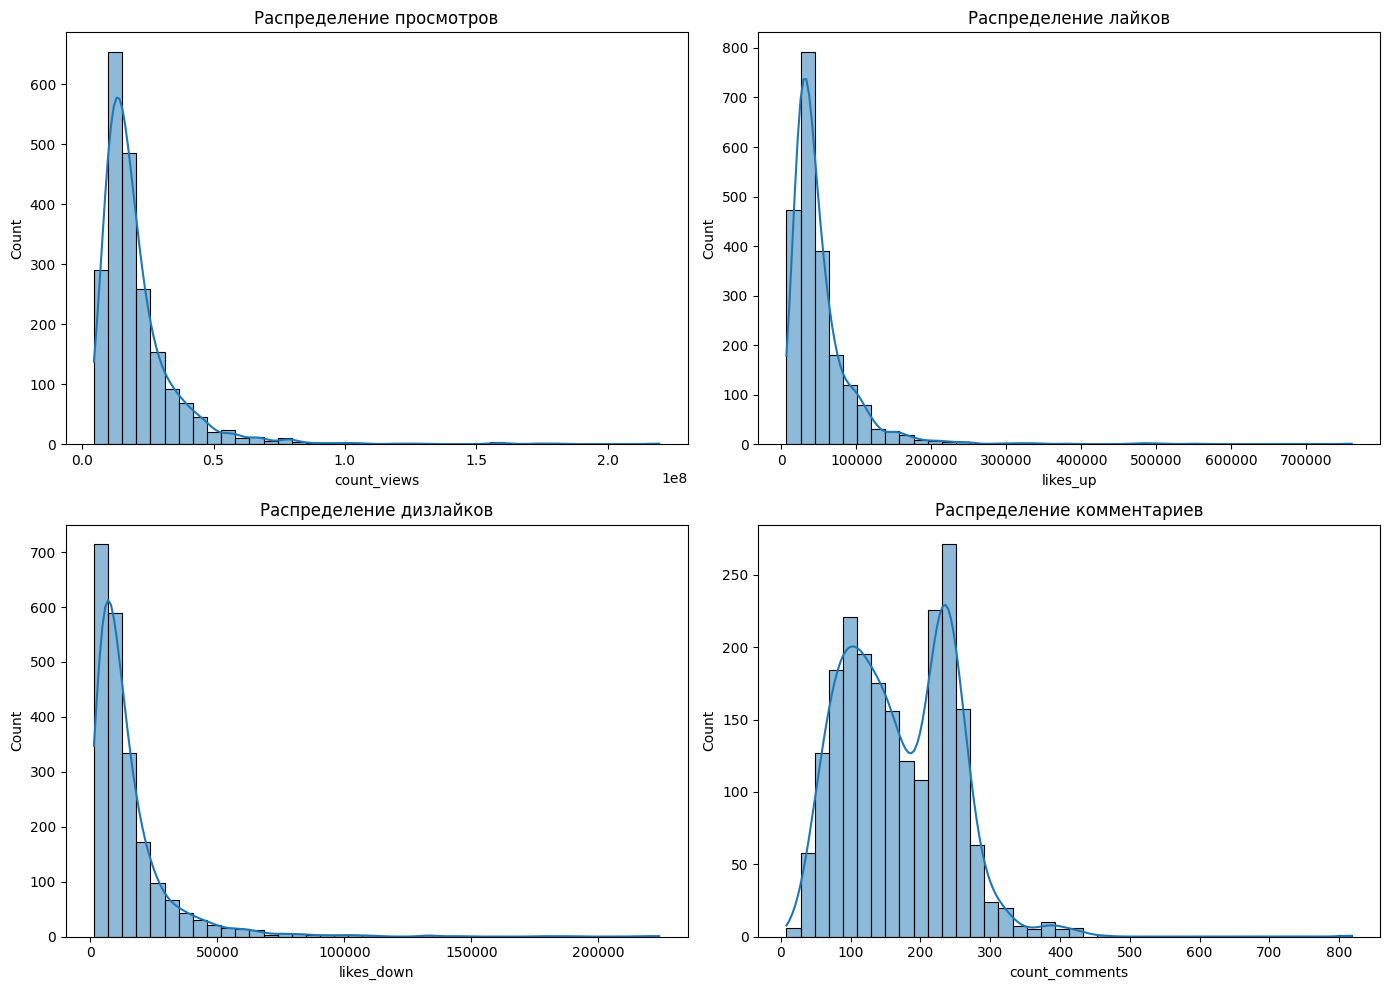

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df_eda["count_views"], bins=40, kde=True, ax=ax[0, 0])
ax[0, 0].set_title("Распределение просмотров")

sns.histplot(df_eda["likes_up"], bins=40, kde=True, ax=ax[0, 1])
ax[0, 1].set_title("Распределение лайков")

sns.histplot(df_eda["likes_down"], bins=40, kde=True, ax=ax[1, 0])
ax[1, 0].set_title("Распределение дизлайков")

sns.histplot(df_eda["count_comments"], bins=40, kde=True, ax=ax[1, 1])
ax[1, 1].set_title("Распределение комментариев")

plt.tight_layout()
plt.show()



*   Распределение просмотров: огромное количество видео имеет очень мало просмотров: пик около 0–200 тыс., более 600 видео имеют меньше 100 тыс. просмотров
*   Распределение лайков: 99+% видео получают минимальное количество лайков. Попадание в «сотни тысяч» лайков — редчайшее исключение
*   Распределение дизлайков: дизлайков в среднем намного меньше, чем лайков (соотношение лайк/дизлайк очень высокое). Контент редко собирает больше 100–150 тыс. дизлайков.
*   Распределение комментариев: Значительная часть видео имеет 100–300 комментариев. Комментарии распределяются гораздо равномернее, чем просмотры и лайки. Даже невирусные видео часто получают хотя бы 100–200 комментариев. Активность в комментариях выше, чем можно было бы ожидать, глядя на просмотры и лайки.





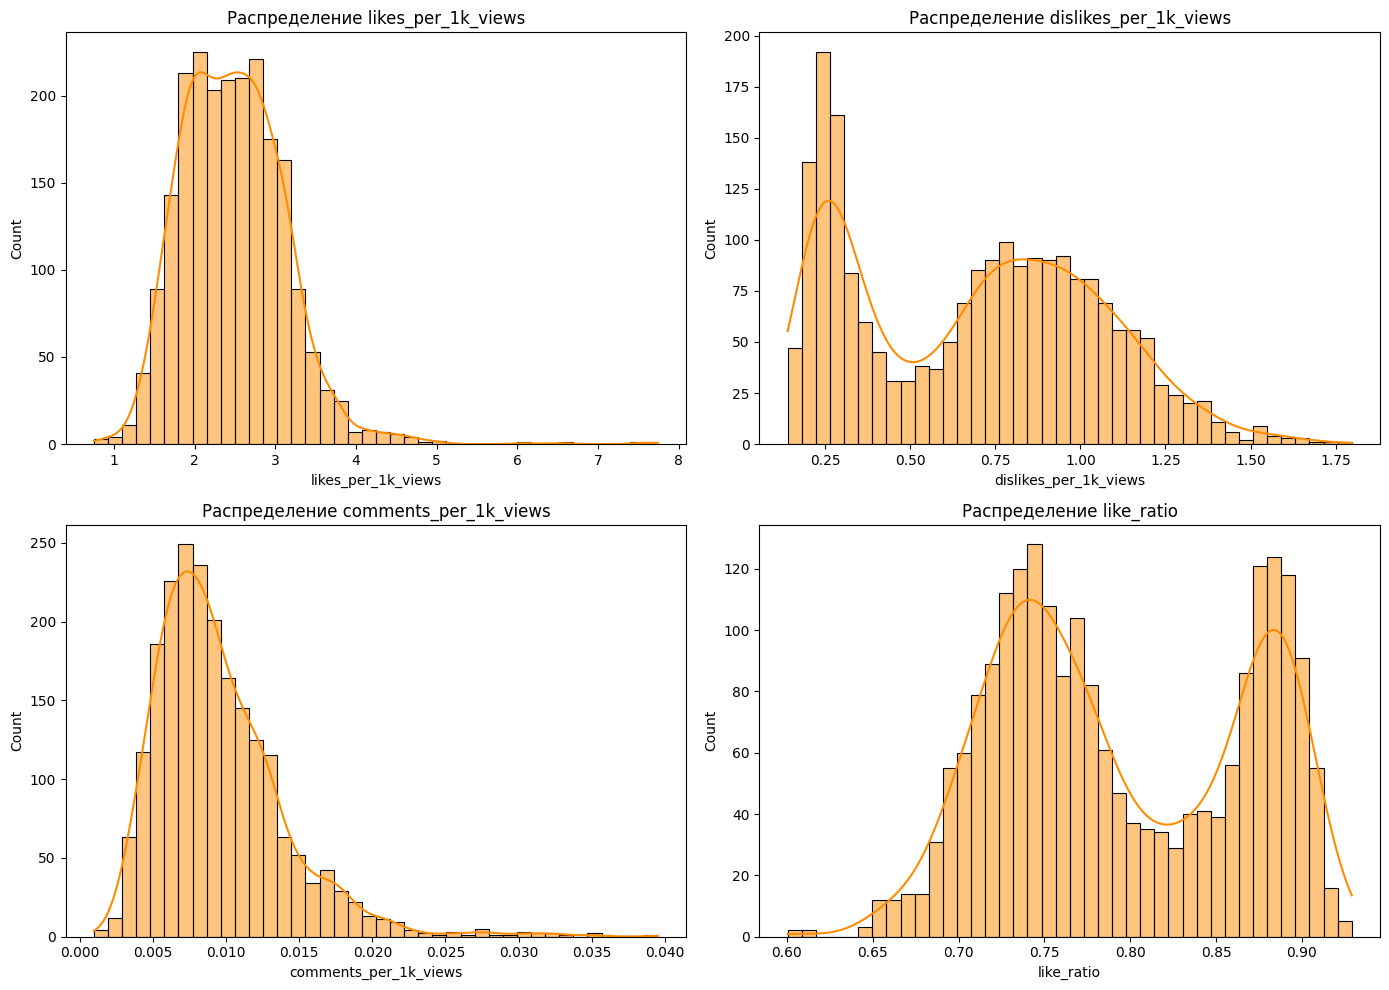

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df_eda["likes_per_1k_views"], bins=40, kde=True, ax=ax[0, 0], color='darkorange')
ax[0, 0].set_title("Распределение likes_per_1k_views")

sns.histplot(df_eda["dislikes_per_1k_views"], bins=40, kde=True, ax=ax[0, 1], color='darkorange')
ax[0, 1].set_title("Распределение dislikes_per_1k_views")

sns.histplot(df_eda["comments_per_1k_views"], bins=40, kde=True, ax=ax[1, 0], color='darkorange')
ax[1, 0].set_title("Распределение comments_per_1k_views")

sns.histplot(df_eda["like_ratio"], bins=40, kde=True, ax=ax[1, 1], color='darkorange')
ax[1, 1].set_title("Распределение like_ratio")

plt.tight_layout()
plt.show()


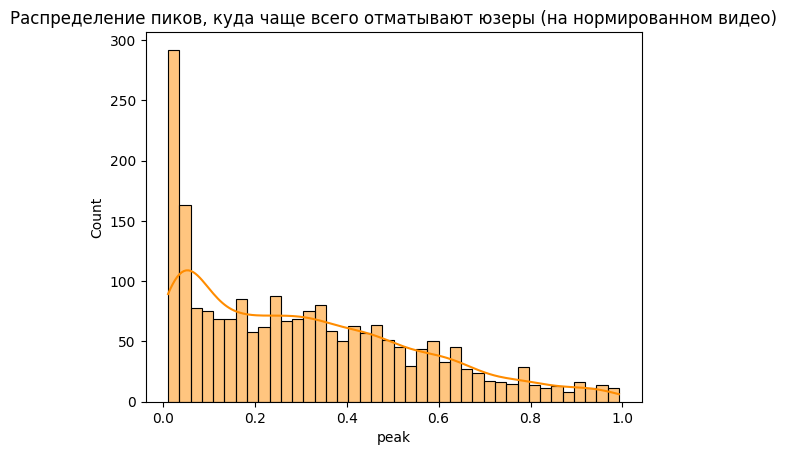

In [ ]:
sns.histplot(df_eda["peak"], bins=40, kde=True, color='darkorange')
plt.title("Распределение пиков, куда чаще всего отматывают юзеры (на нормированном видео)")

plt.show()

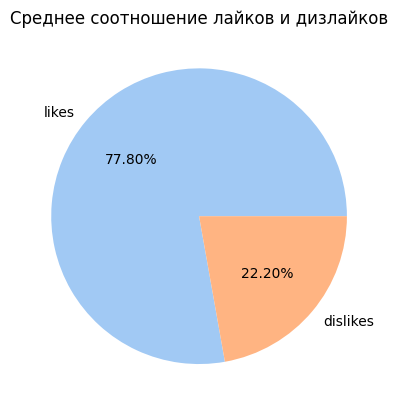

In [ ]:
likes, dislikes = df['likes_up'], df['likes_down']
mean_like_vs_dislike = [likes.mean(), dislikes.mean()]
labels = ['likes', 'dislikes']
colors = sns.color_palette('pastel')
plt.pie(mean_like_vs_dislike, labels=labels, colors=colors, autopct='%.2f%%')
plt.title('Среднее соотношение лайков и дизлайков')

plt.show()

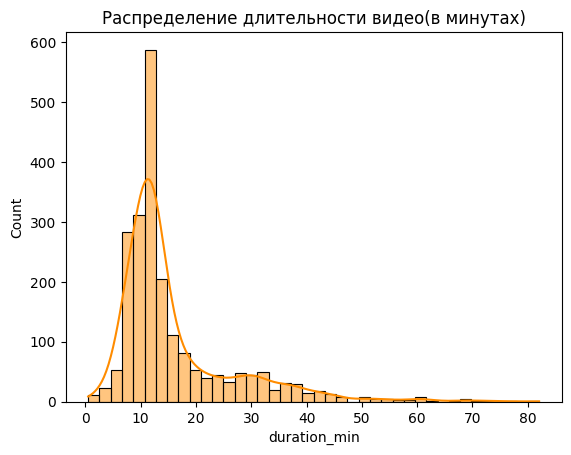

In [ ]:
plt.figure()
sns.histplot(df_eda["duration_min"], bins=40, kde=True, color='darkorange')
plt.title("Распределение длительности видео(в минутах)")

plt.show()

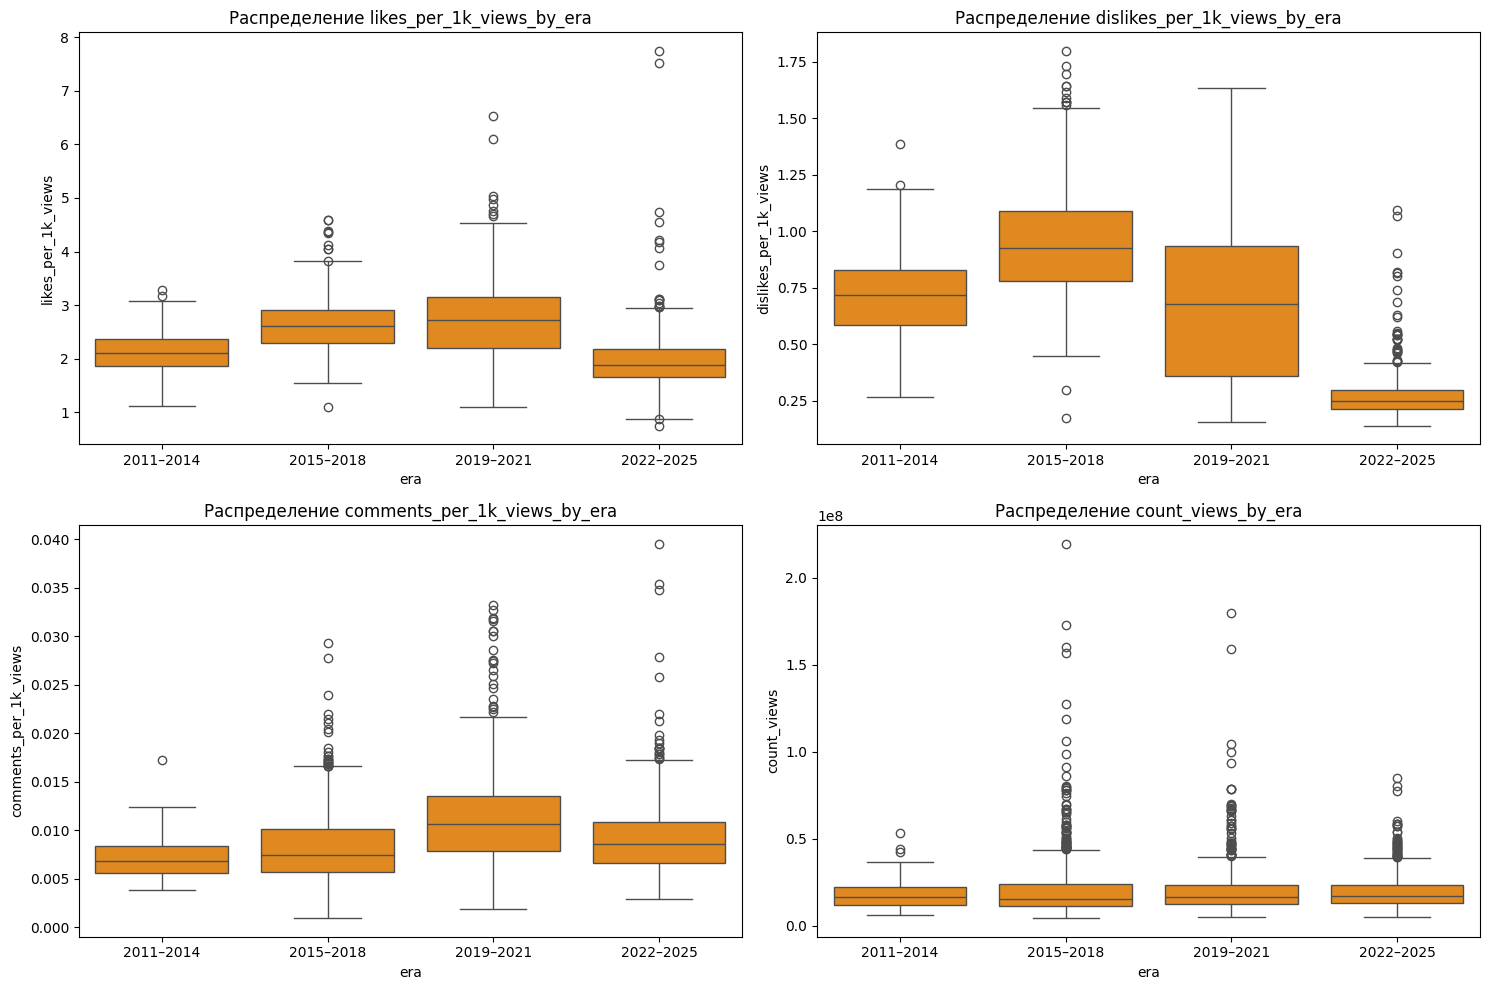

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
era_order = ["2011–2014", "2015–2018", "2019–2021", "2022–2025"]

sns.boxplot(data=df_eda, x="era", y="likes_per_1k_views", order=era_order,ax=ax[0, 0], color='darkorange')
ax[0, 0].set_title("Распределение likes_per_1k_views_by_era")

sns.boxplot(data=df_eda, x="era", y="dislikes_per_1k_views", order=era_order,ax=ax[0, 1], color='darkorange')
ax[0, 1].set_title("Распределение dislikes_per_1k_views_by_era")

sns.boxplot(data=df_eda, x="era", y="comments_per_1k_views", order=era_order,ax=ax[1, 0], color='darkorange')
ax[1, 0].set_title("Распределение comments_per_1k_views_by_era")

sns.boxplot(data=df_eda, x="era", y="count_views", order=era_order,ax=ax[1, 1], color='darkorange')
ax[1, 1].set_title("Распределение count_views_by_era")

plt.tight_layout()
plt.show()

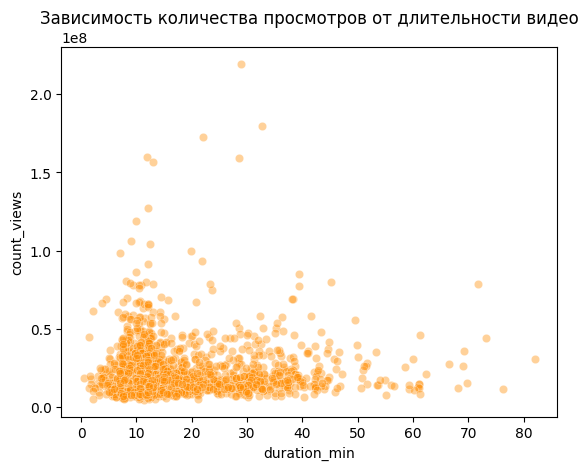

In [ ]:
plt.figure()
sns.scatterplot(data=df_eda, x="duration_min", y="count_views", alpha=0.4, color='darkorange')
plt.title("Зависимость количества просмотров от длительности видео")
plt.show()


In [ ]:
df['duration_min'].max()

82.05

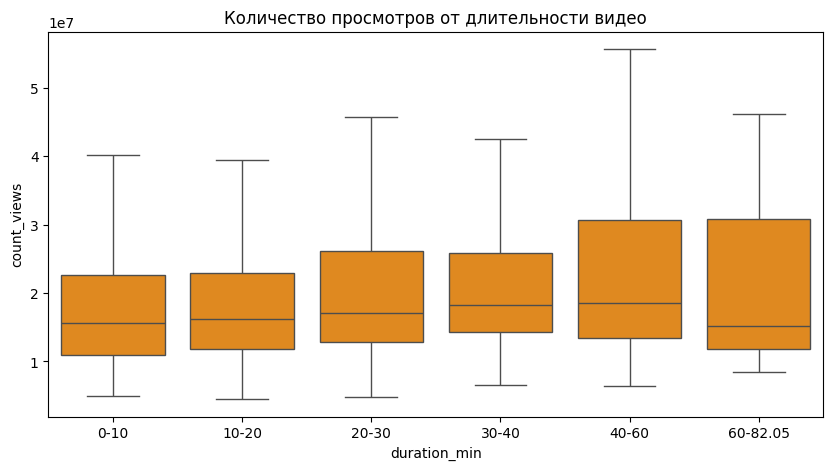

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df_eda, x="dur_bin", y="count_views", showfliers=False, color='darkorange')
plt.title("Количество просмотров от длительности видео")
plt.xlabel("duration_min")

plt.show()

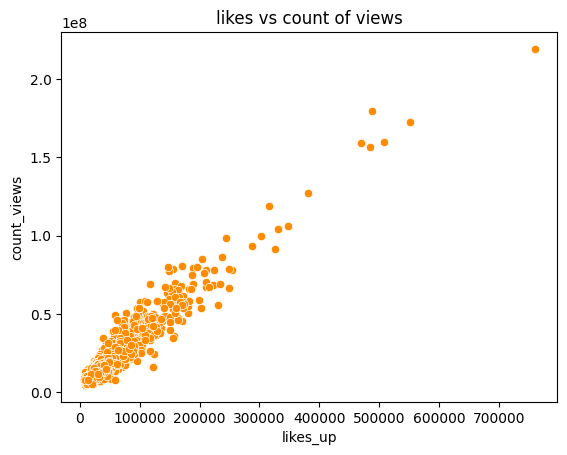

In [ ]:
plt.figure()
sns.scatterplot(data=df_eda, x="likes_up", y="count_views", color='darkorange')
plt.title("likes vs count of views")

plt.show()

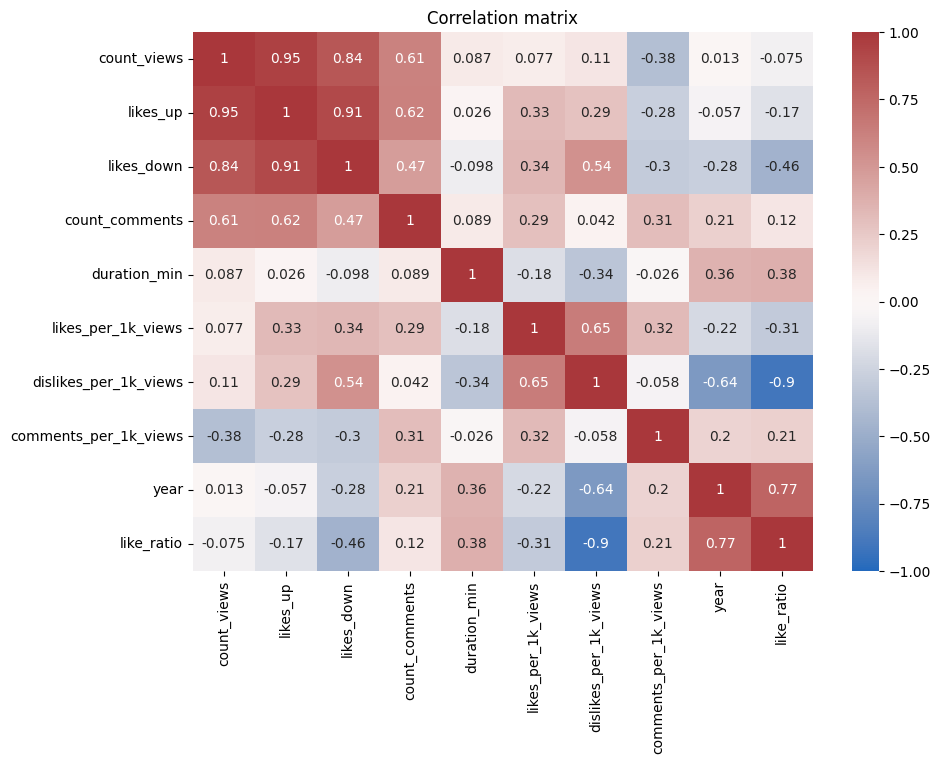

In [ ]:
num_cols = ["count_views","likes_up","likes_down","count_comments","duration_min", "likes_per_1k_views", "dislikes_per_1k_views", "comments_per_1k_views","year", "like_ratio"]
plt.figure(figsize=(10,7))
sns.heatmap(df_eda[num_cols].corr(), annot=True, vmin=-1, vmax=1, center=0, cmap="vlag")
plt.title("Correlation matrix")

plt.show()

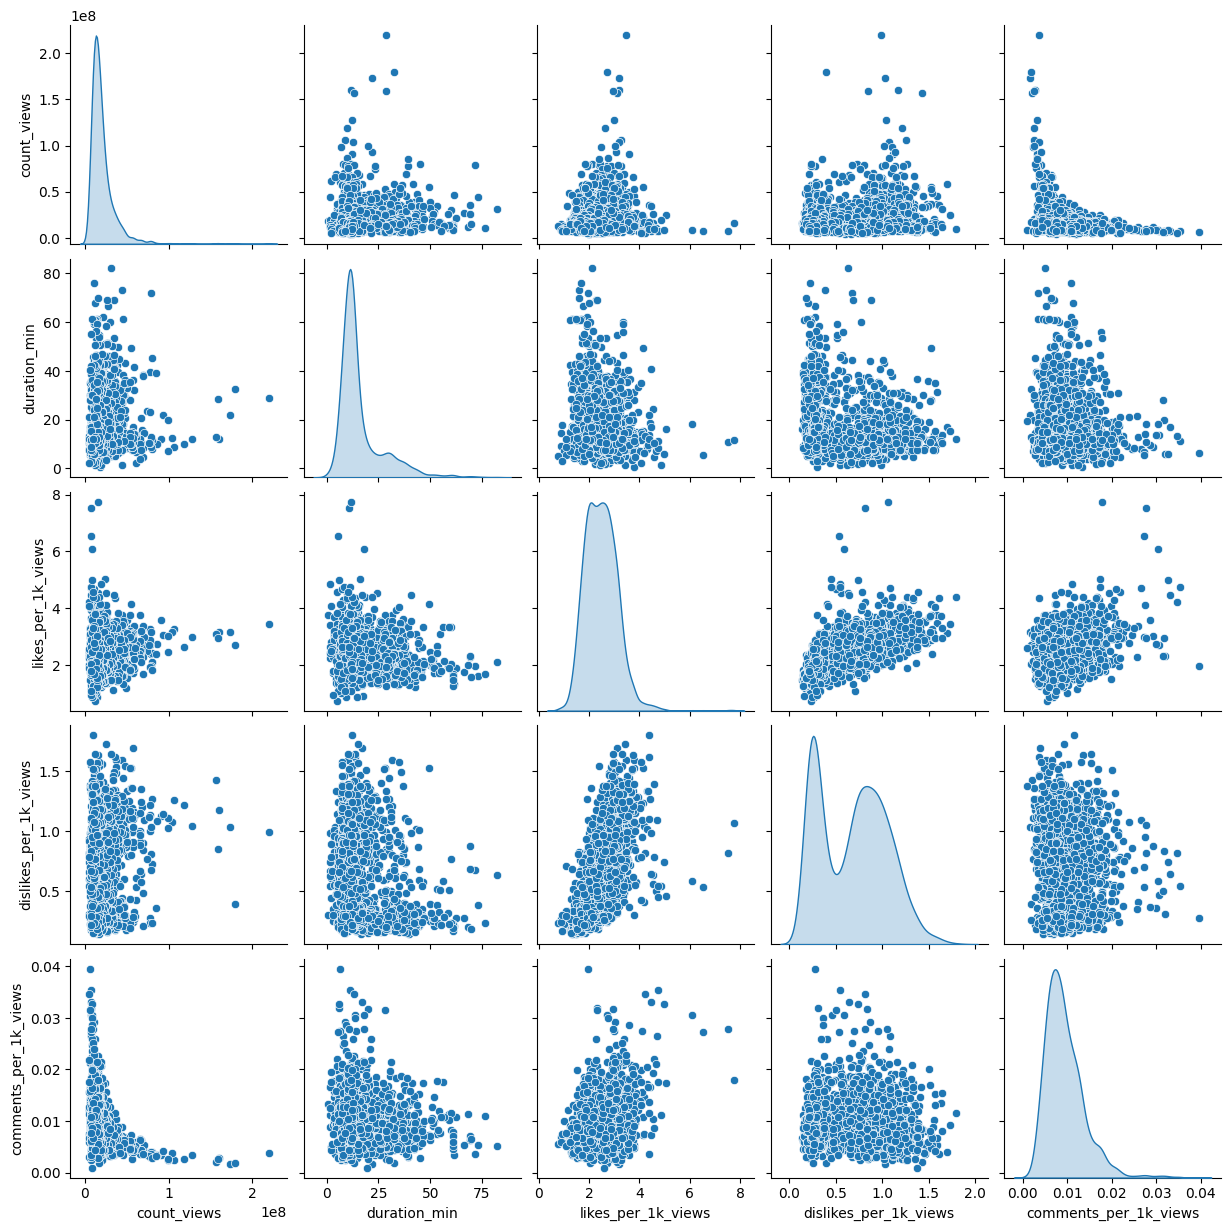

In [ ]:
cols = ["count_views", "duration_min", "likes_per_1k_views", "dislikes_per_1k_views", "comments_per_1k_views"]
sns.pairplot(df_eda[cols], diag_kind="kde")

plt.show()

Вовлеченность

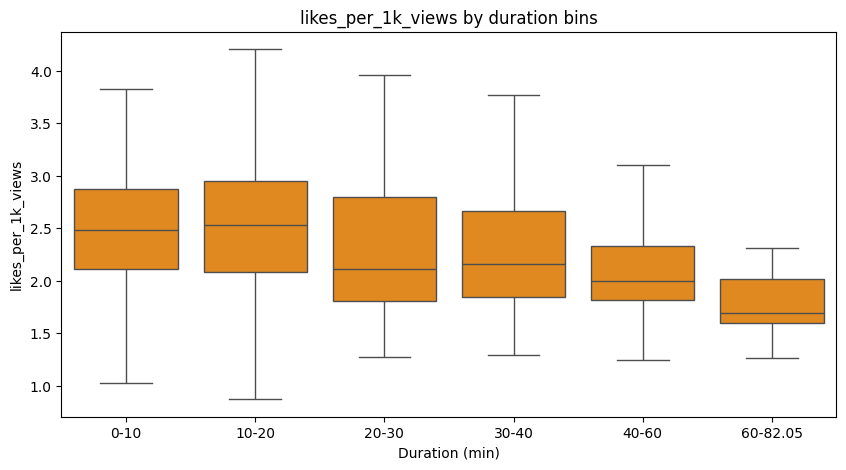

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df_eda, x="dur_bin", y="likes_per_1k_views", showfliers=False, color='darkorange')
plt.title("likes_per_1k_views by duration bins")
plt.xlabel("Duration (min)")
plt.show()


Анализ дизлайков

In [ ]:
df_more_dislike = df_eda[df_eda['likes_down'] > df_eda['likes_up']]
print(f"Кол-во видео, в которых дизлайков больше, чем лайков:  {len(df_more_dislike)}")

Кол-во видео, в которых дизлайков больше, чем лайков:  0


Топ тегов в тех видео, которые набрали больше всего дизлайков

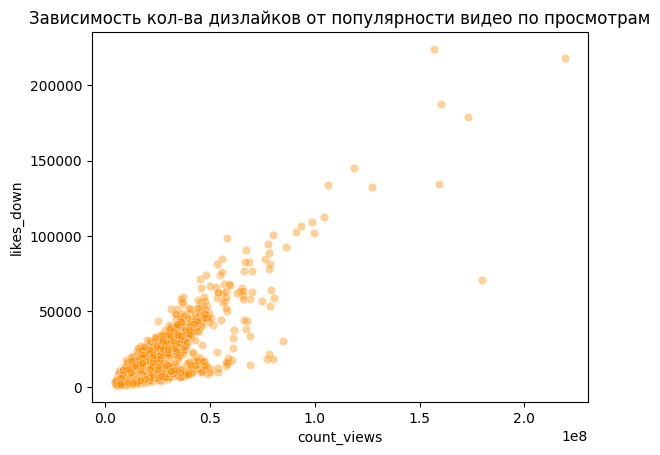

In [ ]:
plt.figure()
sns.scatterplot(data=df_eda, x="count_views", y="likes_down", alpha=0.4, color='darkorange')
plt.title("Зависимость кол-ва дизлайков от популярности видео по просмотрам")
plt.show()

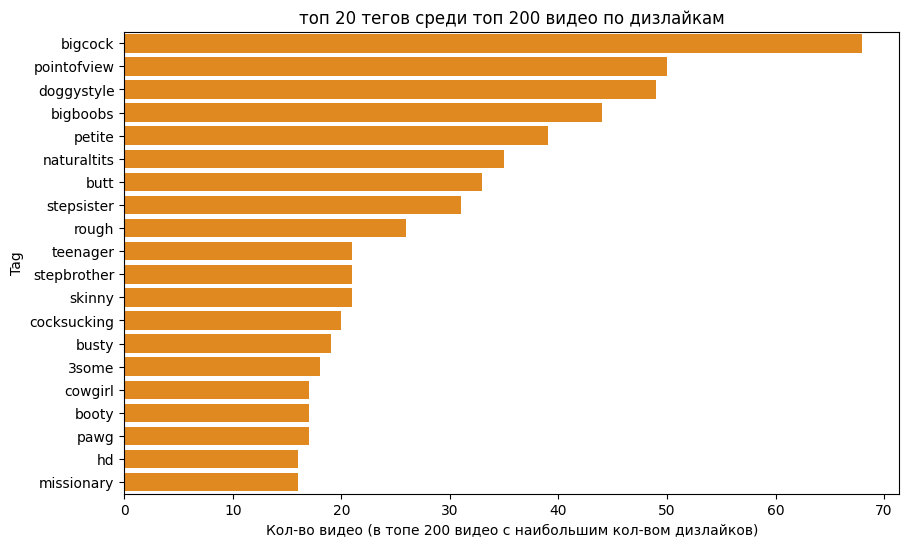

In [ ]:
tag_cols = [c for c in df_eda.columns if c.startswith("tag_")]

top_disliked = df_eda.sort_values("dislikes_per_1k_views", ascending=False).head(200)

tag_counts = top_disliked[tag_cols].sum().sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=tag_counts.values, y=[t.replace("tag_", "") for t in tag_counts.index], color='darkorange')
plt.title(f"топ 20 тегов среди топ 200 видео по дизлайкам")
plt.xlabel("Кол-во видео (в топе 200 видео с наибольшим кол-вом дизлайков)")
plt.ylabel("Tag")

plt.show()

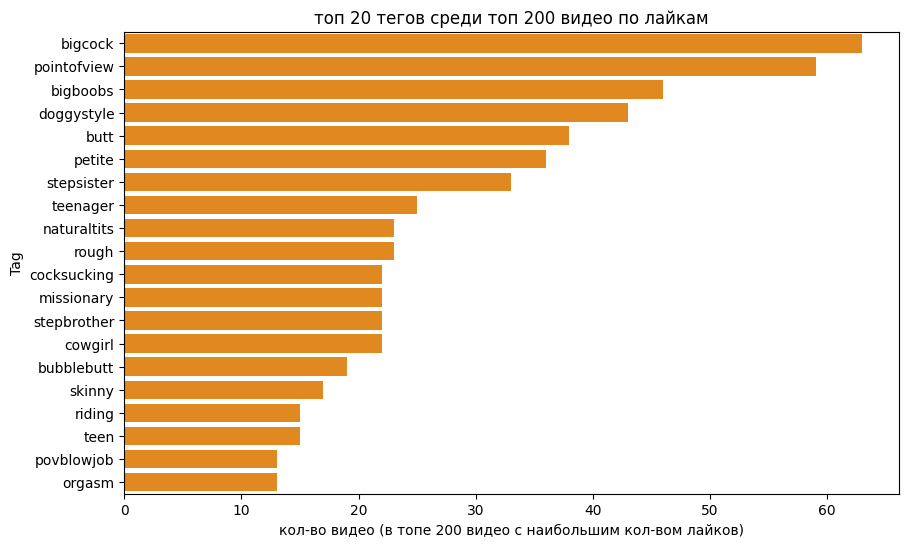

In [ ]:
top_by_likes = df_eda.sort_values("likes_per_1k_views", ascending=False).head(200)
tag_counts_views = top_by_likes[tag_cols].sum().sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=tag_counts_views.values, y=[c.replace("tag_", "") for c in tag_counts_views.index], color='darkorange')
plt.title(f"топ 20 тегов среди топ 200 видео по лайкам")
plt.xlabel("кол-во видео (в топе 200 видео с наибольшим кол-вом лайков)")
plt.ylabel("Tag")

plt.show()

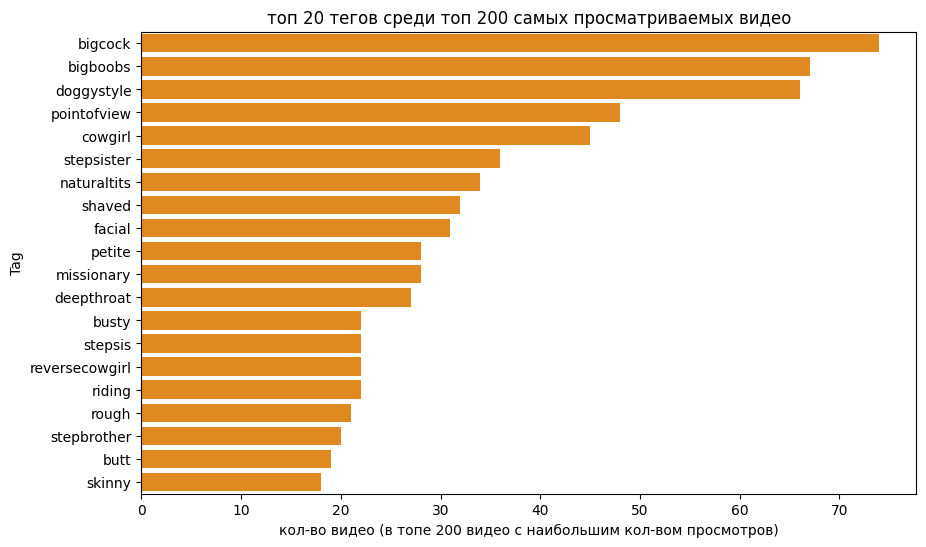

In [ ]:
top_by_views = df_eda.sort_values("count_views", ascending=False).head(200)
tag_counts_views = top_by_views[tag_cols].sum().sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=tag_counts_views.values, y=[c.replace("tag_", "") for c in tag_counts_views.index], color='darkorange')
plt.title(f"топ 20 тегов среди топ 200 самых просматриваемых видео")
plt.xlabel("кол-во видео (в топе 200 видео с наибольшим кол-вом просмотров)")
plt.ylabel("Tag")

plt.show()

корреляция между просмотрами и кол-вом лайков 0,95 - почти одиновые результаты

Категории

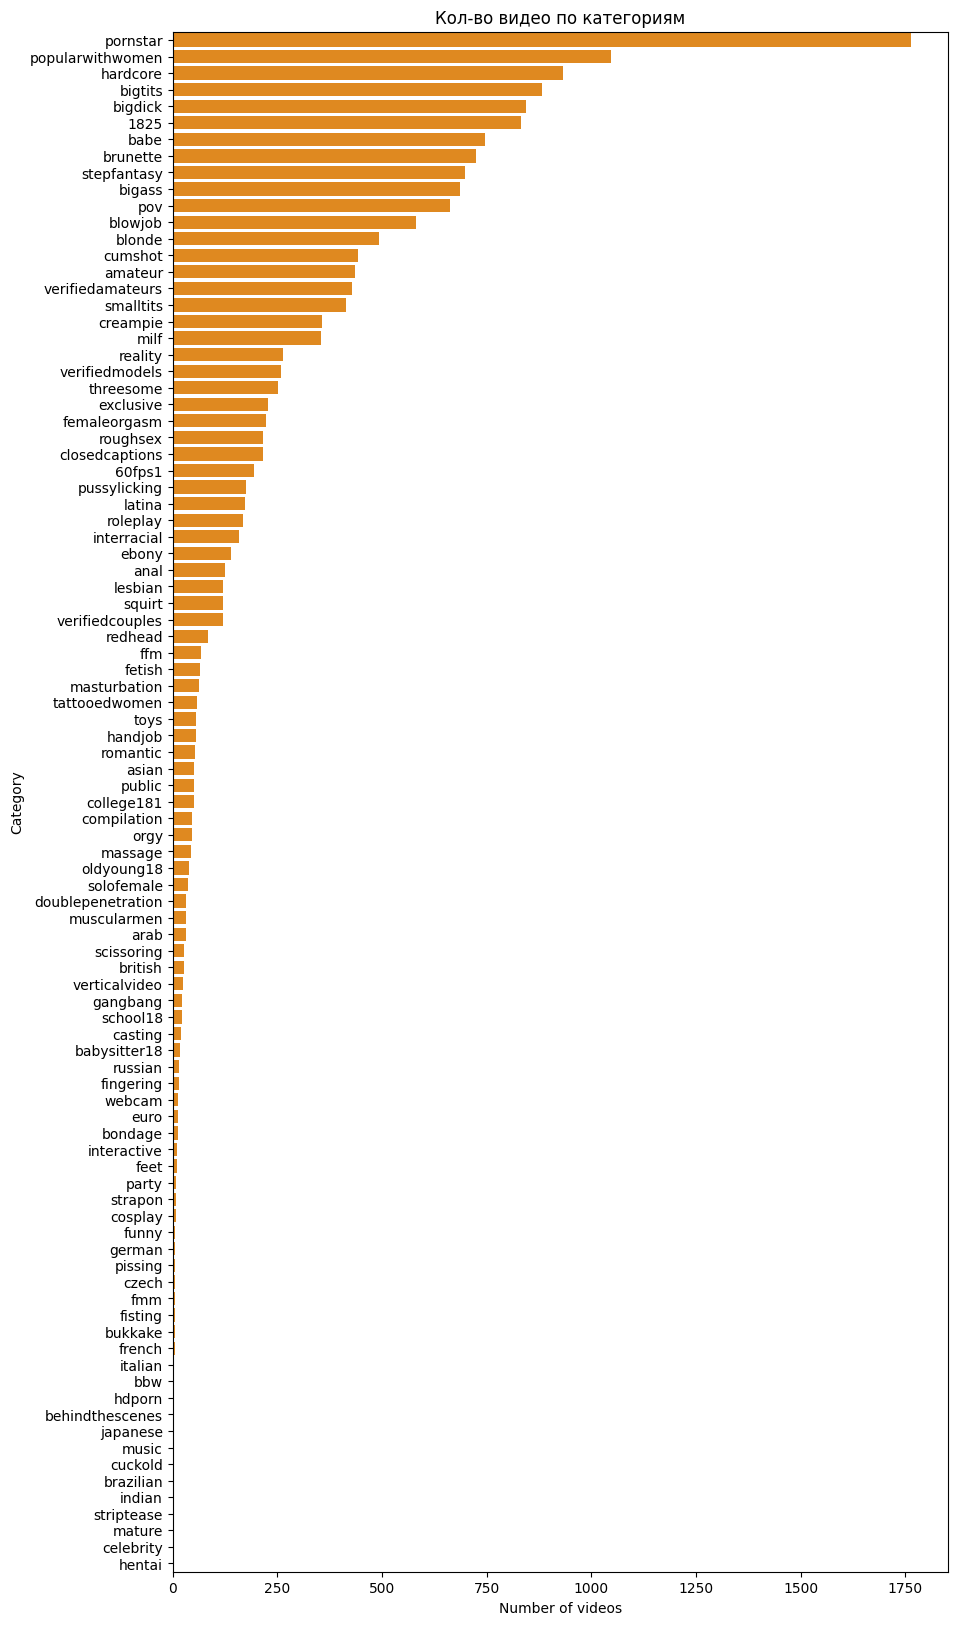

In [ ]:
cat_cols = [c for c in df_eda.columns if c.startswith("cat_")]

cat_counts = df_eda[cat_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 20))
sns.barplot(x=cat_counts.values, y=[c.replace("cat_", "") for c in cat_counts.index], color='darkorange')
plt.title(f"Кол-во видео по категориям")
plt.xlabel("Number of videos")
plt.ylabel("Category")

plt.show()

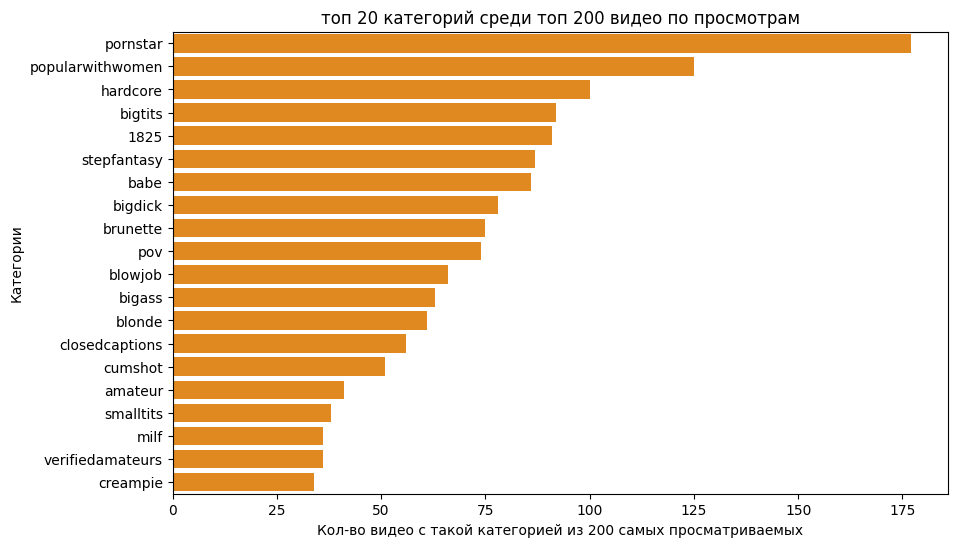

In [ ]:
cat_cols = [c for c in df_eda.columns if c.startswith("cat_")]

top_viewed = df_eda.sort_values("count_views", ascending=False).head(200)

cat_counts = top_viewed[cat_cols].sum().sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=cat_counts.values, y=[t.replace("cat_", "") for t in cat_counts.index], color='darkorange')
plt.title("топ 20 категорий среди топ 200 видео по просмотрам")
plt.xlabel("Кол-во видео с такой категорией из 200 самых просматриваемых")
plt.ylabel("Категории")

plt.show()

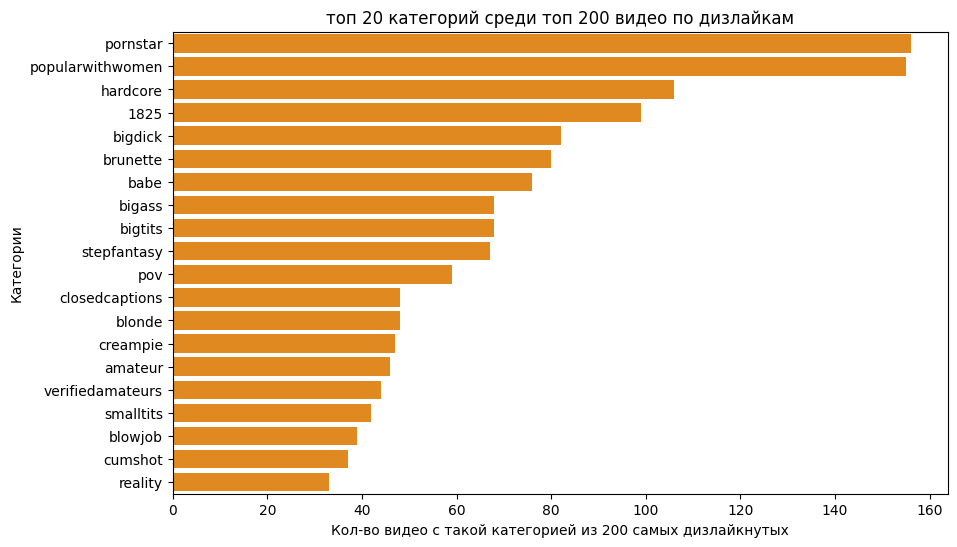

In [ ]:
cat_counts = top_disliked[cat_cols].sum().sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=cat_counts.values, y=[t.replace("cat_", "") for t in cat_counts.index], color='darkorange')
plt.title(f"топ 20 категорий среди топ 200 видео по дизлайкам")
plt.xlabel("Кол-во видео с такой категорией из 200 самых дизлайкнутых")
plt.ylabel("Категории")

plt.show()

примерно одинаково с кол-вом просмотров тк кол-во просмотров и кол-во дизлайков сильно коррелирует

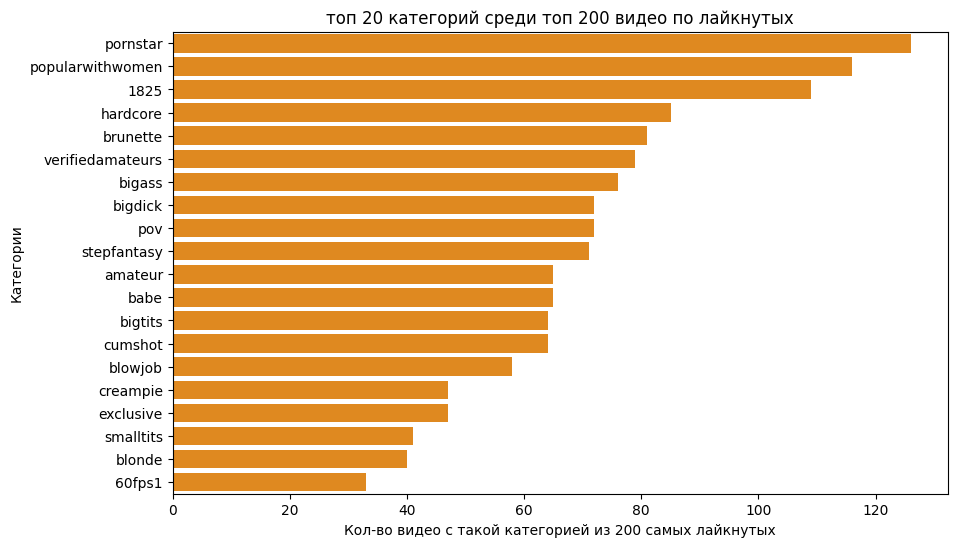

In [ ]:
cat_counts = top_by_likes[cat_cols].sum().sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=cat_counts.values, y=[t.replace("cat_", "") for t in cat_counts.index], color='darkorange')
plt.title(f"топ 20 категорий среди топ 200 видео по лайкнутых")
plt.xlabel("Кол-во видео с такой категорией из 200 самых лайкнутых")
plt.ylabel("Категории")

plt.show()

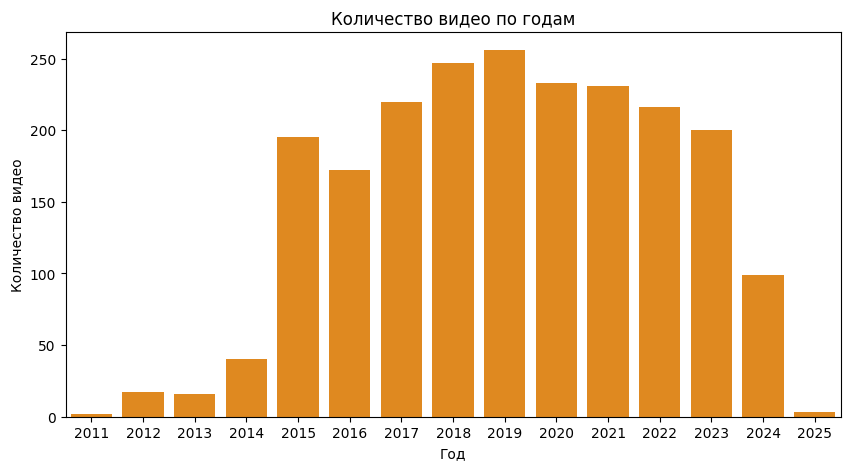

,count
year,
2019,256
2020,233
2021,231
2022,216
2023,200
2024,99
2025,3


In [ ]:
year_counts = df_eda["year"].value_counts().sort_index()

plt.figure(figsize=(10,5))
sns.barplot(x=year_counts.index, y=year_counts.values, color='darkorange')
plt.title("Количество видео по годам")
plt.xlabel("Год")
plt.ylabel("Количество видео")



plt.show()

year_counts[8:]

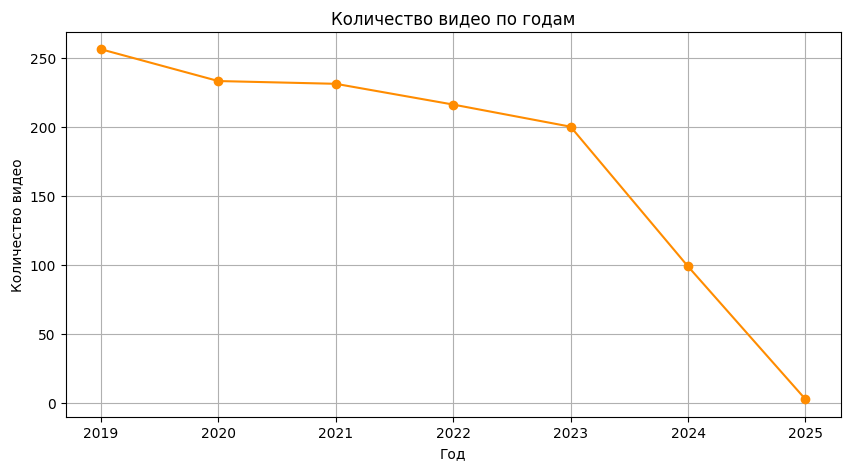

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(year_counts.index[8:], year_counts.values[8:], marker='o', color='darkorange')
plt.title("Количество видео по годам")
plt.xlabel("Год")
plt.ylabel("Количество видео")
plt.grid(True)
plt.show()


In [ ]:
df_eda.columns
cat_cols = [c for c in df_eda.columns if c.startswith("cat_")]
cat_cols

['cat_1825',
 'cat_60fps1',
 'cat_amateur',
 'cat_anal',
 'cat_arab',
 'cat_asian',
 'cat_babe',
 'cat_babysitter18',
 'cat_bbw',
 'cat_behindthescenes',
 'cat_bigass',
 'cat_bigdick',
 'cat_bigtits',
 'cat_blonde',
 'cat_blowjob',
 'cat_bondage',
 'cat_brazilian',
 'cat_british',
 'cat_brunette',
 'cat_bukkake',
 'cat_casting',
 'cat_celebrity',
 'cat_closedcaptions',
 'cat_college181',
 'cat_compilation',
 'cat_cosplay',
 'cat_creampie',
 'cat_cuckold',
 'cat_cumshot',
 'cat_czech',
 'cat_doublepenetration',
 'cat_ebony',
 'cat_euro',
 'cat_exclusive',
 'cat_feet',
 'cat_femaleorgasm',
 'cat_fetish',
 'cat_ffm',
 'cat_fingering',
 'cat_fisting',
 'cat_fmm',
 'cat_french',
 'cat_funny',
 'cat_gangbang',
 'cat_german',
 'cat_handjob',
 'cat_hardcore',
 'cat_hdporn',
 'cat_hentai',
 'cat_indian',
 'cat_interactive',
 'cat_interracial',
 'cat_italian',
 'cat_japanese',
 'cat_latina',
 'cat_lesbian',
 'cat_massage',
 'cat_masturbation',
 'cat_mature',
 'cat_milf',
 'cat_muscularmen',
 'ca

In [ ]:
cat_cols = [c for c in df_eda.columns if c.startswith("cat_")]

min_n = 5  # минимум видео в каждом году для категории 5
inc_categories = []

for c in cat_cols:
    tmp = df_eda.loc[df_eda[c] == 1, ["year", "count_views"]].copy()
    tmp = tmp[tmp["year"].isin([2022, 2023, 2024])]

    # проверим, что в каждом году есть достаточно наблюдений
    counts = tmp["year"].value_counts()
    if any(counts.get(y, 0) < min_n for y in [2022, 2023, 2024]):
        continue

    mean_by_year = tmp.groupby("year")["count_views"].mean()

    v22, v23, v24 = mean_by_year.loc[2022], mean_by_year.loc[2023], mean_by_year.loc[2024]

    if (v24 > v23) and (v23 > v22):
        inc_categories.append(c.replace("cat_", ""))


print("Категории с ростом mean_views 2022 < 2023 < 2024:", len(inc_categories))
print(inc_categories)

Категории с ростом mean_views 2022 < 2023 < 2024: 14
['babe', 'bigass', 'bigdick', 'bigtits', 'creampie', 'hardcore', 'milf', 'pornstar', 'pov', 'roleplay', 'squirt', 'tattooedwomen', 'threesome', 'verifiedmodels']


категория | рейтинг, которая она принимает в топ 20 самых просматриваемых видео

babe - 7

bigass - 12

bigdick - 8

bigtits - 4

creampie - 20

hardcore - 3

milf - 17

pornstar - 1

pov - 10

roleplay - нет в топ 20

verifiedmodels - нет в топ 20

squirt - нет в топ 20

tattooedwomen - нет в топ 20

threesome - нет в топ 20

для данных категорий выявлен тренд на увеличение просмотров с 22 по 24 года. категории, которые не представлены большим количеством просмотров, могут стать точкой роста для порноиндустрии.

In [ ]:
print(f"кол-во видео по категории roleplay: {(df_eda['cat_roleplay'] == 1).sum()}")
counts_22 = df_eda.loc[(df_eda['cat_roleplay'] == 1) & (df_eda['year'] >= 2022),'year'].value_counts().sort_index()
print(f"кол-во видео по категории roleplay по годам (с 2022):{counts_22}")


кол-во видео по категории roleplay: 167
кол-во видео по категории roleplay по годам (с 2022):year
2022    14
2023    29
2024    24
2025     3
Name: count, dtype: int64


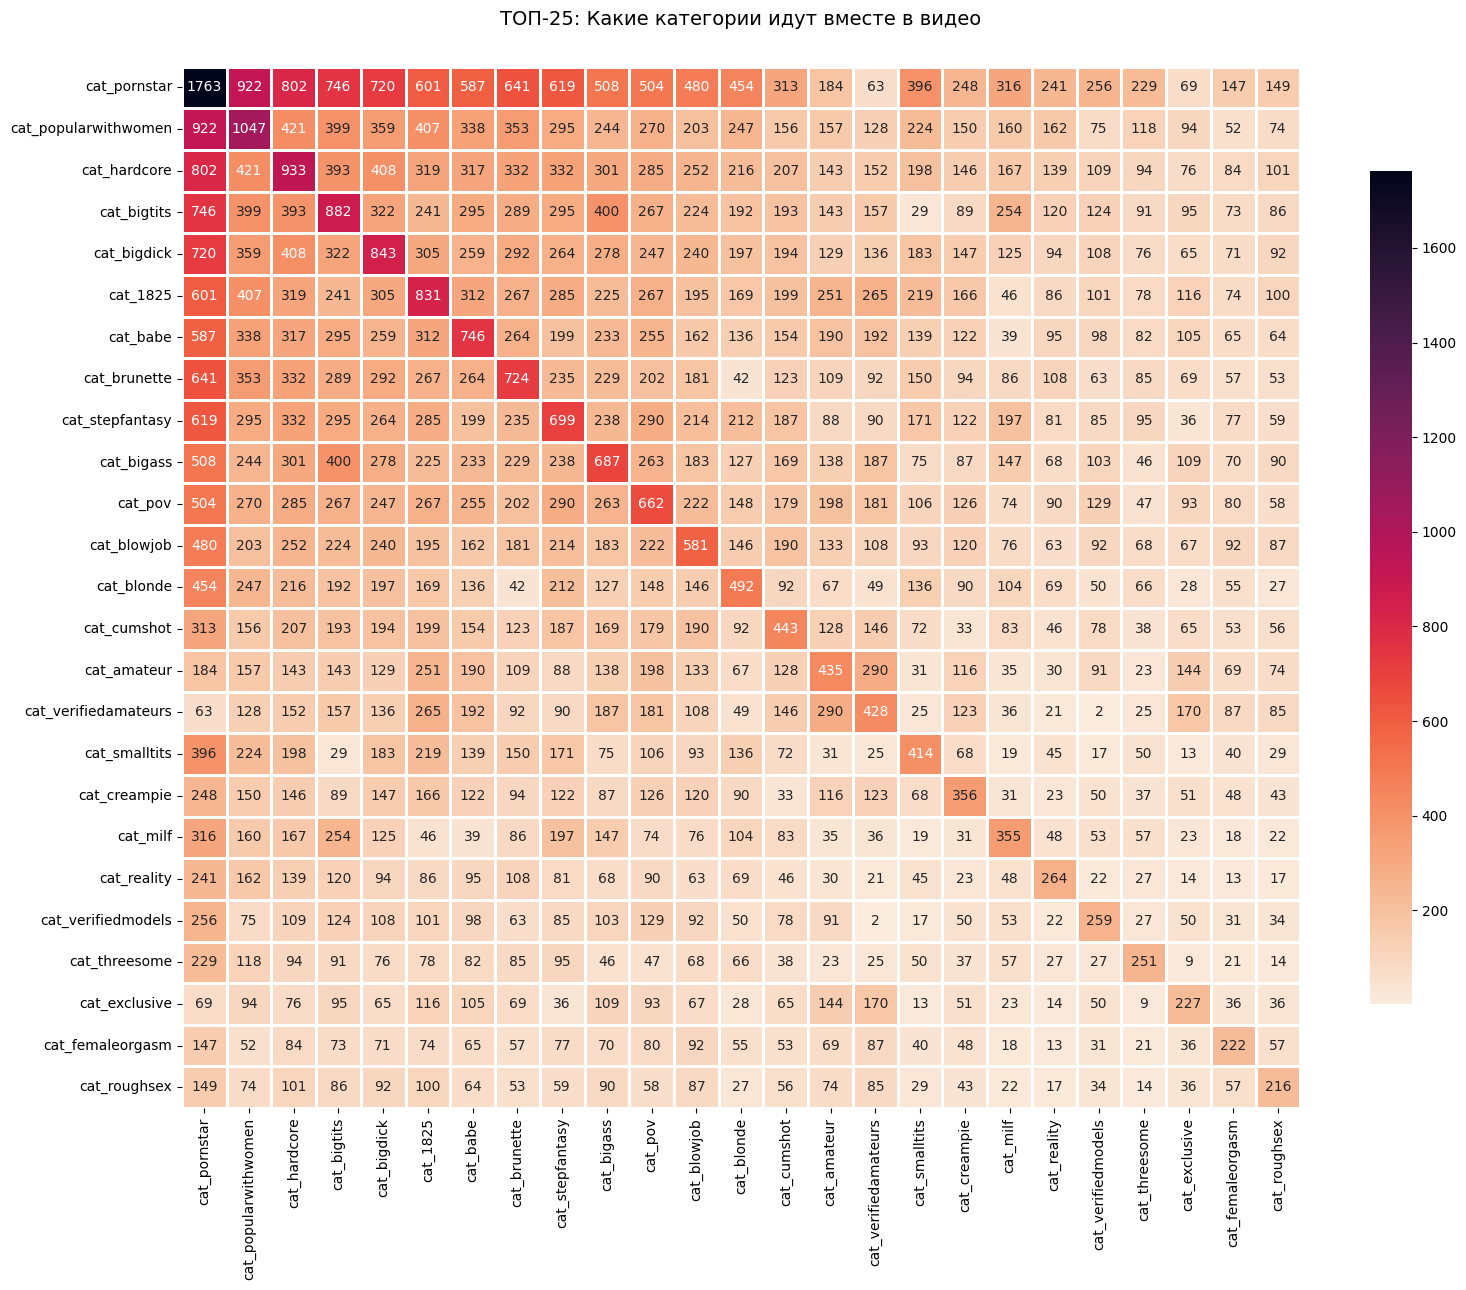

In [ ]:
cat_cols = [c for c in df_eda.columns if c.startswith('cat_')]
cat_matrix = df_eda[cat_cols]

top25 = cat_matrix.sum().sort_values(ascending=False).head(25).index
cooc = cat_matrix[top25].T.dot(cat_matrix[top25])

plt.figure(figsize=(16, 13))
sns.heatmap(cooc, annot=True, fmt="d", cmap="rocket_r", linewidths=0.8, cbar_kws={'shrink': 0.8})

plt.title("ТОП-25: Какие категории идут вместе в видео", fontsize=14, pad=30)
plt.xticks(rotation=90, ha='center')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

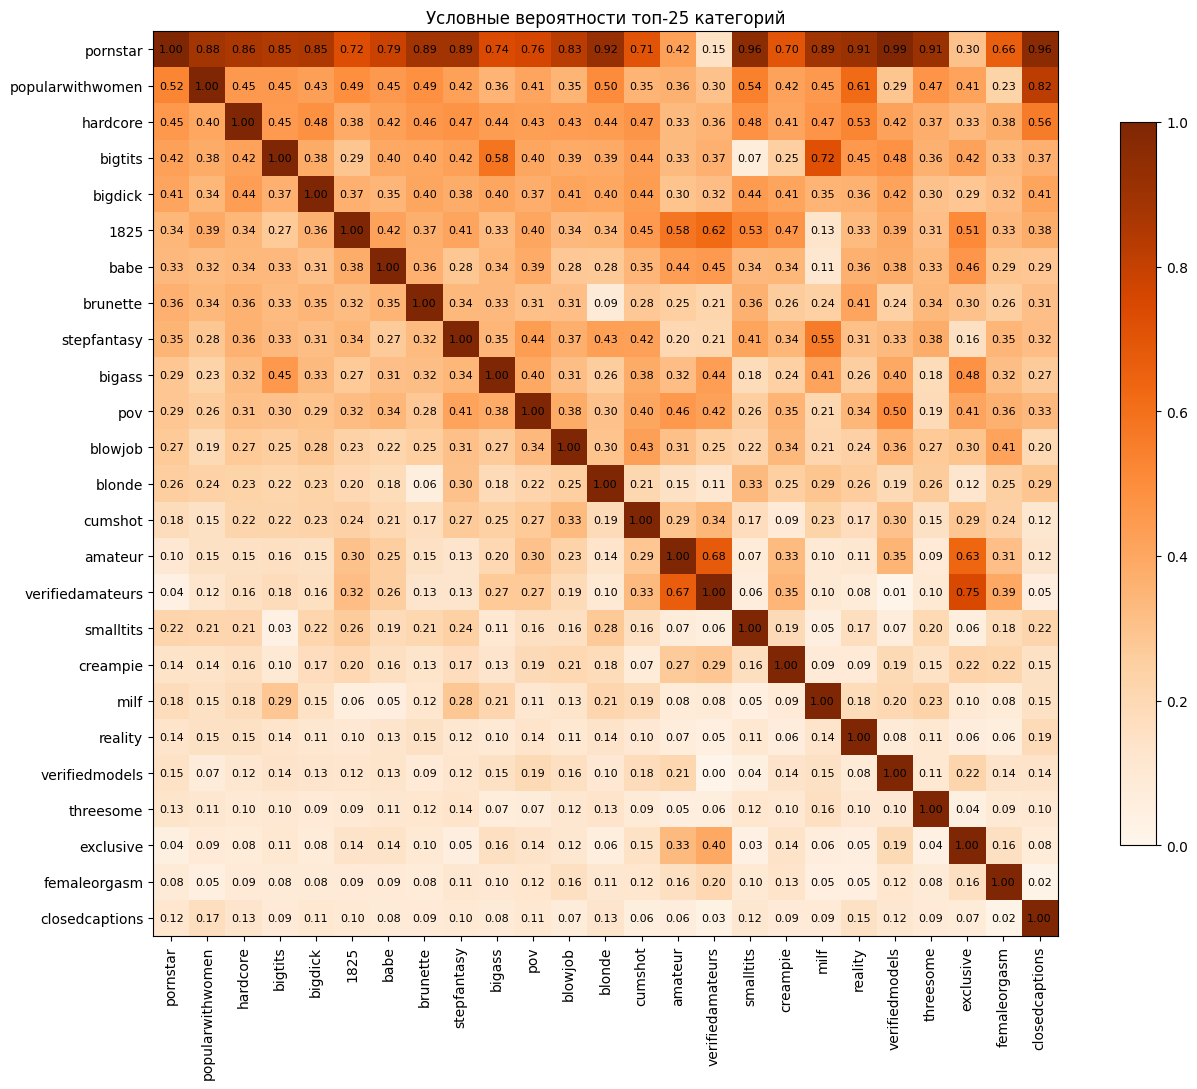

In [ ]:
cat_cols = [c for c in df_eda.columns if c.startswith('cat_')]
cat_matrix = df_eda[cat_cols].astype(int)

freq = cat_matrix.sum()
cooc = cat_matrix.T @ cat_matrix

# Условная вероятность P(B|A)
cond_prob = cooc / freq

top25 = freq.nlargest(25).index
cond_top = cond_prob.loc[top25, top25]

plt.figure(figsize=(14, 11))
plt.imshow(cond_top, cmap='Oranges', vmin=0, vmax=1)

plt.colorbar(shrink=0.8)
plt.xticks(range(len(top25)), [c.replace('cat_', '') for c in top25], rotation=90)
plt.yticks(range(len(top25)), [c.replace('cat_', '') for c in top25])

plt.title('Условные вероятности топ-25 категорий')
for i in range(len(top25)):
    for j in range(len(top25)):
        plt.text(j, i, f'{cond_top.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8, color='black')

plt.tight_layout()
plt.show()

## Постановка и проверка гипотез

### Гипотеза 1

**Предпосылка к гипотезе 1**

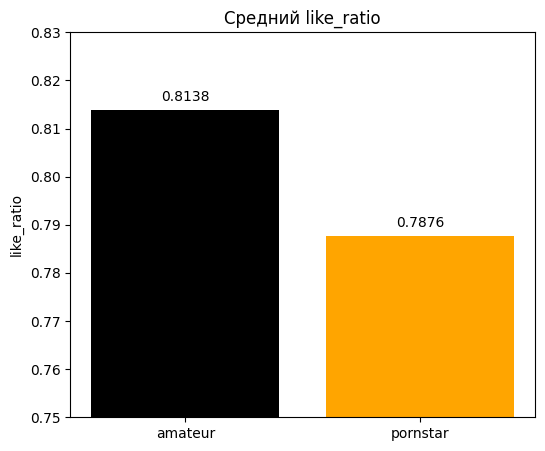

In [ ]:
mean_amateur  = df_eda[(df_eda['cat_amateur'] == 1) & (df_eda['cat_pornstar'] == 0)]['like_ratio'].mean()
mean_pornstar = df_eda[(df_eda['cat_pornstar'] == 1) & (df_eda['cat_amateur'] == 0)]['like_ratio'].mean()

plt.figure(figsize=(6, 5))
plt.bar(['amateur', 'pornstar'], [mean_amateur, mean_pornstar], color=['black', 'orange'])
plt.title('Средний like_ratio')
plt.ylabel('like_ratio')
plt.ylim(0.75, 0.83)

plt.text(0, mean_amateur + 0.002, f'{mean_amateur:.4f}', ha='center')
plt.text(1, mean_pornstar + 0.002, f'{mean_pornstar:.4f}', ha='center')

plt.show()

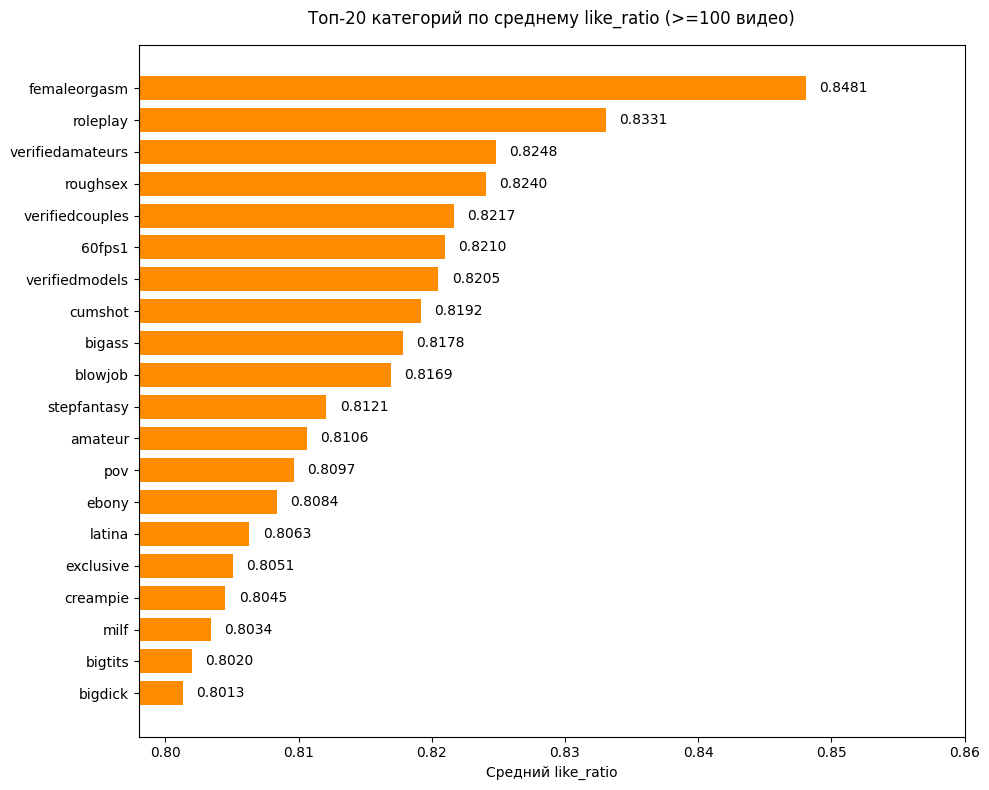

In [ ]:
cat_cols = [c for c in df_eda.columns if c.startswith('cat_')]
stat = []

for col in cat_cols:
    cat = col.replace('cat_', '')
    sub = df_eda[df_eda[col] == 1]
    if len(sub) >= 100:
        stat.append({
            'category': cat,
            'n': len(sub),
            'mean_ratio': sub['like_ratio'].mean()
        })

top20 = pd.DataFrame(stat).sort_values('mean_ratio', ascending=False).head(20)

plt.figure(figsize=(10, 8))
plt.barh(top20['category'], top20['mean_ratio'], color='darkorange', height=0.75)

for i, (cat, val) in enumerate(zip(top20['category'], top20['mean_ratio'])):
    plt.text(val + 0.001, i, f'{val:.4f}', va='center', fontsize=10)

plt.xlabel('Средний like_ratio')
plt.title('Топ-20 категорий по среднему like_ratio (>=100 видео)', pad=15, fontsize=12)
plt.xlim(0.798, 0.860)
plt.gca().invert_yaxis()  # от самого высокого сверху

plt.tight_layout()
plt.show()

**Гипотеза 1. Профессиональные и любительские видео**

Многие считают, что любительское порно вызывает больше доверия и эмоционального отклика, чем профессиональное.

$H_0$: Среднее значение `like_ratio` в видео с категорией `amateur` не отличается от среднего значения `like_ratio` в видео с категорией `pornstar`

$H_1$: Среднее значение `like_ratio` в видео с категорией `amateur` отличается от среднего значения `like_ratio` в видео с категорией `pornstar`

Для начала взглянем на распределения

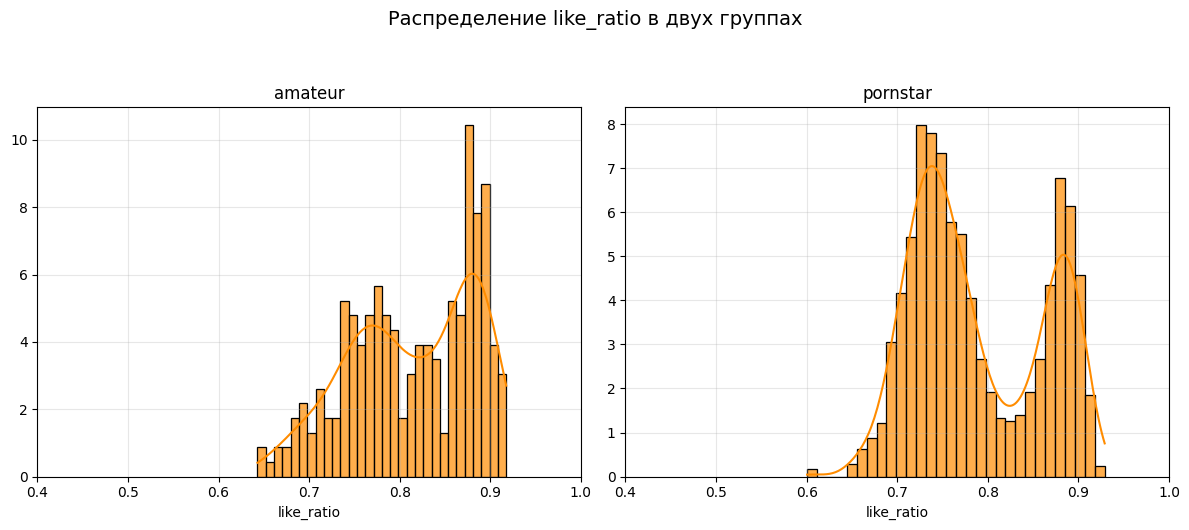

In [ ]:
amateur  = df_eda[(df_eda['cat_amateur'] == 1) & (df_eda['cat_pornstar'] == 0)]['like_ratio']
pornstar = df_eda[(df_eda['cat_pornstar'] == 1) & (df_eda['cat_amateur'] == 0)]['like_ratio']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(amateur, kde=True, ax=ax1, color='darkorange', alpha=0.7, bins=30, stat="density")
ax1.set_title(f'amateur', fontsize=12)
ax1.set_xlabel('like_ratio')
ax1.set_ylabel('')
ax1.set_xlim(0.4, 1.0)
ax1.grid(alpha=0.3)

sns.histplot(pornstar, kde=True, ax=ax2, color='darkorange', alpha=0.7, bins=30, stat="density")
ax2.set_title(f'pornstar', fontsize=12)
ax2.set_xlabel('like_ratio')
ax2.set_ylabel('')
ax2.set_xlim(0.4, 1.0)
ax2.grid(alpha=0.3)

fig.suptitle('Распределение like_ratio в двух группах', fontsize=14, y=1.05)

plt.tight_layout()
plt.show()

In [ ]:
amateur = df_eda[(df_eda['cat_amateur'] == 1) & (df_eda['cat_pornstar'] == 0)]['like_ratio']
pornstar = df_eda[(df_eda['cat_pornstar'] == 1) & (df_eda['cat_amateur'] == 0)]['like_ratio']

mu1 = amateur.mean()
mu2 = pornstar.mean()
sigma1 = amateur.std()
sigma2 = pornstar.std()
n1 = len(amateur)
n2 = len(pornstar)

z = (mu1 - mu2) / np.sqrt((sigma1**2 / n1) + (sigma2**2 / n2))

p_value = 1 - stats.norm.cdf(z)

print(f"Z-статистика: {z:.4f}")
print(f"p-value: {p_value:.4e}")

Z-статистика: 5.5741
p-value: 1.2442e-08


`p-value < 0.05`, следовательно, отклоняем $H_0$ и принимаем $H_1$

Итого: среднее значение `like_ratio` в видео с категорией `amateur` отличается от среднего значения `like_ratio` в видео с категорией `pornstar`

### Гипотеза 2

**Предпоссылка к гипотезе 2**

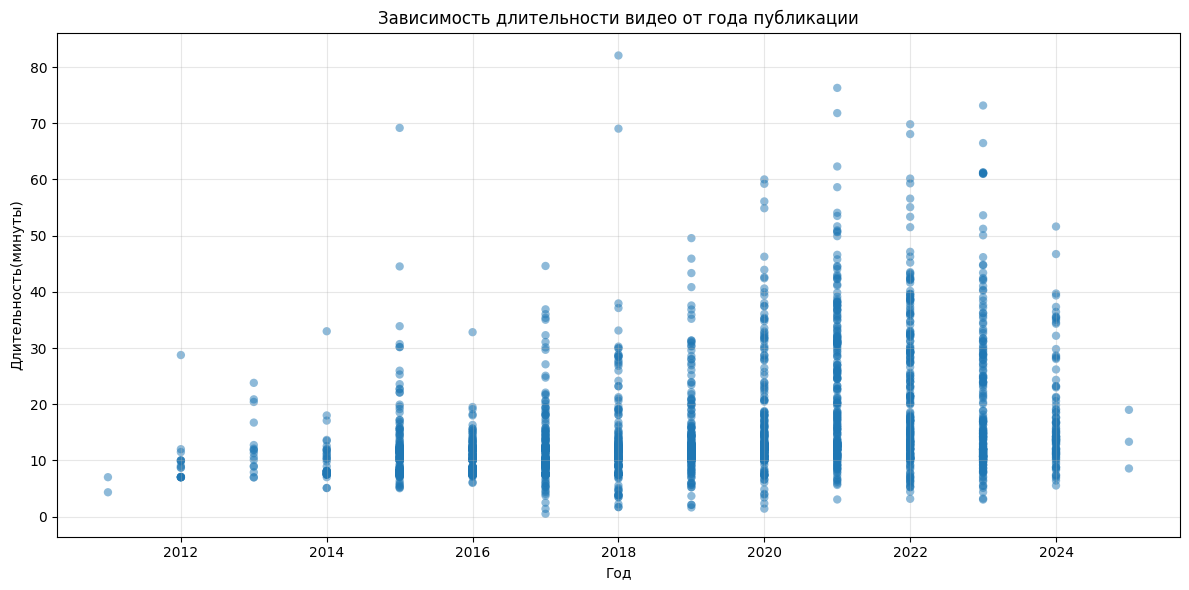

In [ ]:
df['year'] = pd.to_datetime(df['date']).dt.year

plt.figure(figsize=(12, 6))
plt.scatter(df['year'], df['duration_min'], alpha=0.5, edgecolors='none')
plt.xlabel('Год')
plt.ylabel('Длительность(минуты)')
plt.title('Зависимость длительности видео от года публикации')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Гипотеза 2. Изменение длительности видео со временем**

На основе scatterplot можно предположить, что средняя длительность видео изменяется в зависимости от года публикации. Возможно, с развитием платформы и изменением предпочтений аудитории длительность контента увеличивается или уменьшается.

$H_0$: Средняя длительность видео не зависит от года публикации (средние значения `duration_min` одинаковы для разных временных периодов)

$H_1$: Средняя длительность видео зависит от года публикации (средние значения `duration_min` различаются для разных временных периодов)

In [ ]:
from scipy import stats

era_groups = [df_eda[df_eda["era"] == era]["duration_min"].dropna() for era in era_order]

stat, p_value = stats.kruskal(*era_groups)

print(f"Kruskal-Wallis H-statistic: {stat}")
print(f"p-value: {p_value}")

Kruskal-Wallis H-statistic: 380.0256187998626
p-value: 4.693212426187074e-82


`p-value < 0.05`, следовательно, отклоняем $H_0$ и принимаем $H_1$

Итого: средняя длительность видео зависит от года публикации (средние значения `duration_min` различаются для разных временных периодов)

### Гипотеза 3

**Предпоссылка к гипотезе 3**

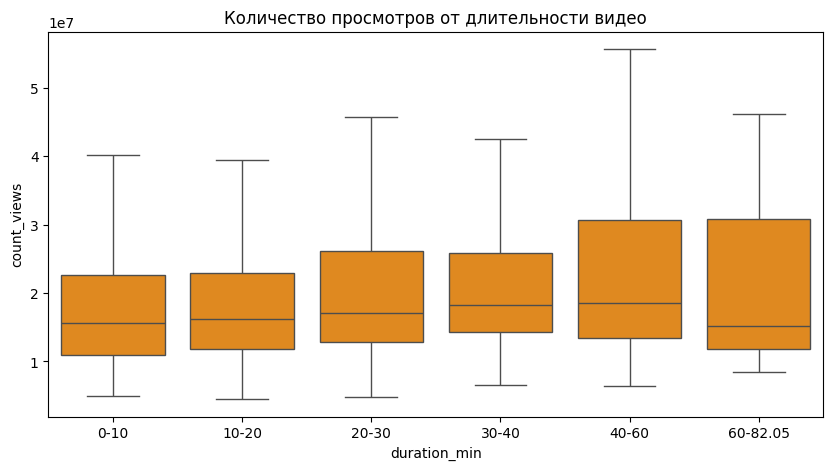

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df_eda, x="dur_bin", y="count_views", showfliers=False, color='darkorange')
plt.title("Количество просмотров от длительности видео")
plt.xlabel("duration_min")

plt.show()

$H_0$: продолжительность видео не влияет на кол-во просмотров видео

$H_1$: видео продолжительностью 40-60 мин привлекают людей больше, чем более длинные или короткие видео

In [ ]:
is_40_60 = (df["duration_min"] > 40) & (df["duration_min"] <= 60)

group_40_60 = df.loc[is_40_60, "count_views"]
group_other = df.loc[~is_40_60, "count_views"]

mw_40_vs_all = stats.mannwhitneyu(
    group_40_60,
    group_other,
    alternative="greater"
)

mw_40_vs_all

MannwhitneyuResult(statistic=np.float64(82491.0), pvalue=np.float64(0.009472747668683642))

`p-value < 0.05`, следовательно, отклоняем $H_0$ и принимаем $H_1$

Итого: видео продолжительностью 40-60 мин привлекают людей больше, чем более длинные или короткие видео  